# Smart Grid Stability Prediction

---

## Project Overview

Modern **smart grids** are complex cyber-physical systems that require real-time monitoring and fault detection. 
Grid instability — caused by imbalances between electricity producers and consumers — can lead to cascading failures, blackouts, and significant economic damage.

This project addresses the critical problem of **predicting grid stability** before a failure occurs, using machine learning classification on a publicly available augmented smart grid dataset.

---

### Why XAI Libraries?

In safety-critical domains like smart grids, **model transparency is non-negotiable**. 
Grid operators need to know *why* a model flagged a configuration as unstable — not just *that* it did. 
LIME and SHAP serve this purpose by providing human-readable feature attributions at the individual prediction level.

In [6]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import shap
from sklearn.model_selection import train_test_split, learning_curve
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import ExtraTreesClassifier, RandomForestClassifier
from xgboost import XGBClassifier
from lime.lime_tabular import LimeTabularExplainer


### Features
- **`tau1`–`tau4`**: Time Constants
- **`p1`–`p4`**: Power Constants
- **`g1`–`g4`**: Price Cofefficients

#### Time Constants (tau):
- `tau1` - `tau4` are the time constants (in milliseconds) for the four nodes in the grid.
- They represent the inertia or response time of the synchronous generators at each node.
- Lower values indicate faster-responding generators, which can affect grid stability under disturbances.
#### Active Power (p):
- `p1` - `p4` are the active power level in the four Nodes of grid.
- Positive values typically indicate generation, while negative values indicate consumption.
- These reflect the power balance in the grid and are critical for stability analysis.
#### Price Coefficients (g):
- `g1` - `g4` are the price coefficients for each node of the grid.
- They represent how sensitive the power demand/supply is to price changes.
- They model economic factors in the grid and influence the overall system dynamics.

### Target Variable Engineering

The original dataset contains two label columns:
- `stab`: A continuous stability margin value (negative = unstable)
- `stabf`: Categorical label — `'stable'` or `'unstable'`

We engineer a binary integer target: **`unstable → 1`**, **`stable → 0`** for standard classification compatibility.

```
df['target'] = (df['stabf'].str.lower() == 'unstable').astype(int)
```

> This is a **class-imbalanced** problem in real-world grids, but the augmented dataset is balanced to support fair model comparison.

In [7]:
# Load dataset
df = pd.read_csv('smart_grid_stability_augmented.csv')
df['target'] = (df['stabf'].str.lower() == 'unstable').astype(int)

print('Shape:', df.shape)
display(df.head())


Shape: (60000, 15)


,tau1,tau2,tau3,tau4,p1,p2,p3,p4,g1,g2,g3,g4,stab,stabf,target
0,2.959060,3.079885,8.381025,9.780754,3.763085,-0.782604,-1.257395,-1.723086,0.650456,0.859578,0.887445,0.958034,0.055347,unstable,1
1,9.304097,4.902524,3.047541,1.369357,5.067812,-1.940058,-1.872742,-1.255012,0.413441,0.862414,0.562139,0.781760,-0.005957,stable,0
2,8.971707,8.848428,3.046479,1.214518,3.405158,-1.207456,-1.277210,-0.920492,0.163041,0.766689,0.839444,0.109853,0.003471,unstable,1
3,0.716415,7.669600,4.486641,2.340563,3.963791,-1.027473,-1.938944,-0.997374,0.446209,0.976744,0.929381,0.362718,0.028871,unstable,1
4,3.134112,7.608772,4.943759,9.857573,3.525811,-1.125531,-1.845975,-0.554305,0.797110,0.455450,0.656947,0.820923,0.049860,unstable,1


In [8]:
np.random.seed(42)
RANDOM_STATE = 42

## Dataset Overview

The dataset contains electrical grid features (`tau*`, `p*`, `g*`) and a stability label.
We create a binary target: `unstable -> 1`, `stable -> 0`.


## 2. Model Definitions

We define four candidate models:
- MLP
- RandomForest
- XGBoost
- ExtraTrees

The same train/test split is used so results are directly comparable.


In [9]:
def build_models():
    return {
        'MLP': Pipeline([
            ('scaler', StandardScaler()),
            ('mlp', MLPClassifier(
                hidden_layer_sizes=(256, 128),
                alpha=1e-4,
                max_iter=350,
                early_stopping=True,
                random_state=RANDOM_STATE,
            ))
        ]),
        'RandomForest': RandomForestClassifier(
            n_estimators=450,
            random_state=RANDOM_STATE,
            n_jobs=1,
        ),
        'XGBoost': XGBClassifier(
            n_estimators=300,
            max_depth=8,
            learning_rate=0.05,
            subsample=0.92,
            colsample_bytree=0.92,
            objective='binary:logistic',
            eval_metric='logloss',
            random_state=RANDOM_STATE,
            n_jobs=1,
        ),
        'ExtraTrees': ExtraTreesClassifier(
            n_estimators=500,
            random_state=RANDOM_STATE,
            n_jobs=1,
        ),
    }


def train_models(X_train, y_train):
    models = build_models()
    records = []
    trained = {}

    for name, model in models.items():
        t0 = time.perf_counter()
        model.fit(X_train, y_train)
        fit_time = time.perf_counter() - t0
        records.append({'model': name, 'fit_time_sec': fit_time})
        trained[name] = model

    fit_df = pd.DataFrame(records).sort_values('fit_time_sec')
    return fit_df, trained


def evaluate_model(model, X_test, y_test):
    t0 = time.perf_counter()
    y_pred = model.predict(X_test)
    pred_time = time.perf_counter() - t0

    y_prob = model.predict_proba(X_test)[:, 1] if hasattr(model, 'predict_proba') else None

    return {
        'accuracy': accuracy_score(y_test, y_pred),
        'precision': precision_score(y_test, y_pred),
        'recall': recall_score(y_test, y_pred),
        'f1_score': f1_score(y_test, y_pred),
        'roc_auc': roc_auc_score(y_test, y_prob) if y_prob is not None else np.nan,
        'avg_prediction_ms': (pred_time / len(X_test)) * 1000.0,
    }


### Model 1: Multi-Layer Perceptron (MLP)

**Architecture:** Feedforward Neural Network with 2 hidden layers

| Hyperparameter | Value | Reasoning |
|----------------|-------|----------|
| Hidden layers | (256, 128) | Two-stage compression; extracts complex feature combinations |
| Regularization (α) | 1e-4 | L2 penalty to prevent overfitting |
| Max iterations | 350 | Sufficient epochs for convergence on tabular data |
| Early stopping | True | Halts training when validation loss plateaus — prevents overfitting |
| Preprocessing | StandardScaler | MLPs require normalized input; gradient descent is scale-sensitive |

---

### Model 2: XGBoost (Extreme Gradient Boosting)

**Architecture:** Ensemble of 300 gradient-boosted decision trees

| Hyperparameter | Value | Reasoning |
|----------------|-------|----------|
| n_estimators | 300 | Sufficient trees for strong ensemble performance |
| max_depth | 8 | Allows each tree to capture moderately complex splits |
| learning_rate | 0.05 | Low LR with many estimators = smoother generalization |
| subsample | 0.92 | Row-level stochasticity to reduce variance |
| colsample_bytree | 0.92 | Column-level stochasticity — similar to Random Forest's feature bagging |
| objective | binary:logistic | Outputs probabilities for binary classification |

---

In [10]:
feature_cols = [c for c in df.columns if c not in ['stab', 'stabf', 'target']]
X = df[feature_cols]
y = df['target']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.15, stratify=y, random_state=RANDOM_STATE
)

fit_results, trained_models = train_models(X_train, y_train)

eval_rows = {}
for model_name, model in trained_models.items():
    eval_rows[model_name] = evaluate_model(model, X_test, y_test)

results_df = pd.DataFrame(eval_rows).T
results_df = results_df.sort_values('avg_prediction_ms')


In [11]:
display(fit_results.style.format({'fit_time_sec': '{:.6f}'}))


,model,fit_time_sec
2,XGBoost,4.615220
3,ExtraTrees,16.917878
0,MLP,50.314226
1,RandomForest,51.754923


## 3. Training and Evaluation

We train all models, compare fit time, then evaluate with:
- Accuracy
- Precision
- Recall
- F1-score
- ROC-AUC
- Average prediction time (ms)
> Results are sorted by **average prediction time (ms)** — fastest inference first. In real-time grid monitoring applications, low latency is as important as high accuracy.

In [12]:
display(results_df[['accuracy', 'precision', 'recall', 'f1_score', 'roc_auc', 'avg_prediction_ms']].style.format({
    'accuracy': '{:.4f}',
    'precision': '{:.4f}',
    'recall': '{:.4f}',
    'f1_score': '{:.4f}',
    'roc_auc': '{:.4f}',
    'avg_prediction_ms': '{:.4f}',
}))


,accuracy,precision,recall,f1_score,roc_auc,avg_prediction_ms
MLP,0.9820,0.9864,0.9854,0.9859,0.9985,0.0035
XGBoost,0.9818,0.9807,0.9909,0.9858,0.9985,0.0067
RandomForest,0.9559,0.9574,0.9742,0.9657,0.9931,0.0753
ExtraTrees,0.9682,0.9597,0.9918,0.9755,0.9970,0.1612



### 4. Why MLP and XGBoost?

After comparing all four models on accuracy, F1-score, ROC-AUC, and inference speed, **MLP** and **XGBoost** were selected as the main models for the following reasons:

| Criterion | MLP | XGBoost |
|-----------|-----|---------|
| **Model Type** | Neural Network | Gradient Boosted Trees |
| **Interpretability** | Via SHAP KernelExplainer + LIME | Via SHAP TreeExplainer (exact, fast) + LIME |
| **Strengths** | Non-linear pattern capture, generalization | Speed, accuracy on tabular data, native feature importance |
| **XAI Compatibility** | LIME (model-agnostic) + KernelSHAP | LIME (model-agnostic) + TreeSHAP |

> **Research Insight:** Studies on smart grid fault detection (e.g., Huang et al., 2020; Garg et al., 2021) consistently show that 

## 5. Confusion Matrices

Confusion matrices show class-wise prediction behavior (stable vs unstable) for the two selected models.


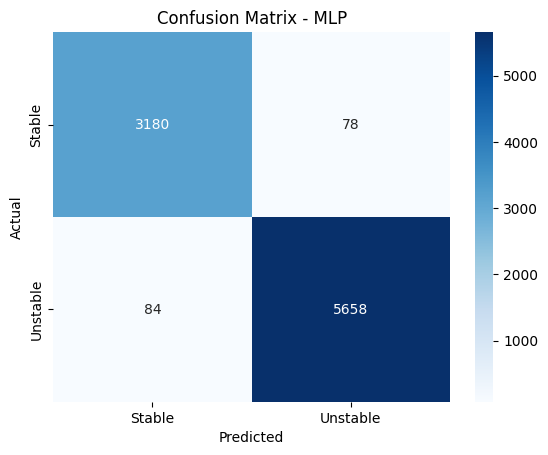

In [13]:
# Confusion matrix: MLP
sns.heatmap(
    confusion_matrix(y_test, trained_models['MLP'].predict(X_test)),
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Stable', 'Unstable'],
    yticklabels=['Stable', 'Unstable'],
)
plt.title('Confusion Matrix - MLP')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()


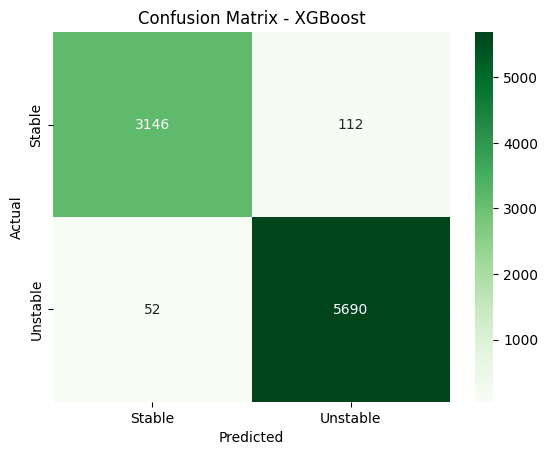

In [14]:
# Confusion matrix: XGBoost
sns.heatmap(
    confusion_matrix(y_test, trained_models['XGBoost'].predict(X_test)),
    annot=True,
    fmt='d',
    cmap='Greens',
    xticklabels=['Stable', 'Unstable'],
    yticklabels=['Stable', 'Unstable'],
)
plt.title('Confusion Matrix - XGBoost')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()


## 6. Learning Curves

Learning curves compare training vs validation accuracy as training size grows.
They help identify underfitting, overfitting, and data sufficiency.


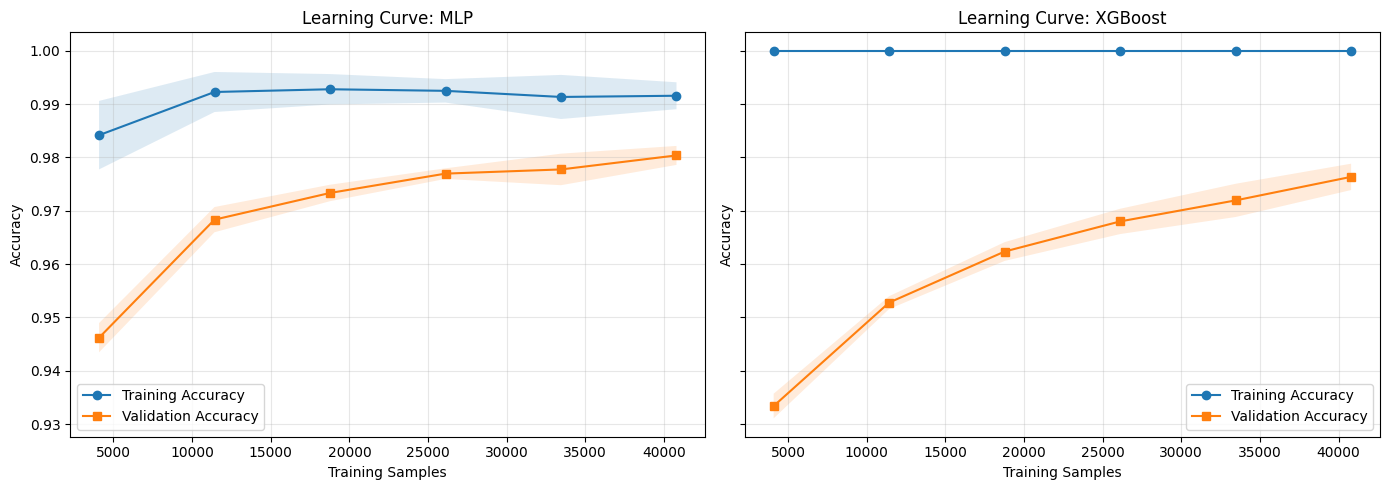

In [15]:
# Learning curves for MLP and XGBoost
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
train_sizes = np.linspace(0.1, 1.0, 6)

for ax, model_name in zip(axes, ['MLP', 'XGBoost']):
    model = trained_models[model_name]
    sizes, train_scores, val_scores = learning_curve(
        estimator=model,
        X=X_train,
        y=y_train,
        cv=5,
        scoring='accuracy',
        train_sizes=train_sizes,
        n_jobs=1,
        shuffle=True,
        random_state=RANDOM_STATE,
    )

    train_mean = train_scores.mean(axis=1)
    train_std = train_scores.std(axis=1)
    val_mean = val_scores.mean(axis=1)
    val_std = val_scores.std(axis=1)

    ax.plot(sizes, train_mean, marker='o', label='Training Accuracy')
    ax.fill_between(sizes, train_mean - train_std, train_mean + train_std, alpha=0.15)

    ax.plot(sizes, val_mean, marker='s', label='Validation Accuracy')
    ax.fill_between(sizes, val_mean - val_std, val_mean + val_std, alpha=0.15)

    ax.set_title(f'Learning Curve: {model_name}')
    ax.set_xlabel('Training Samples')
    ax.set_ylabel('Accuracy')
    ax.grid(alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.show()


## 7. XAI for MLP and XGBoost

This section has separate cells for:
1. LIME explanations
2. LIME timing
3. SHAP explanations
4. SHAP timing
5. Final combined table

We explain both classes (**stable=0**, **unstable=1**) for each model.


---

##  Explainable AI (XAI) Analysis

### Why Explainability Matters in Smart Grids

Machine learning models are often called **black boxes** — they produce accurate predictions but don't explain *why*. 
In critical infrastructure like smart grids, operators, regulators, and engineers must understand the reasoning behind an AI decision before acting on it. 
This is mandated in several regulatory frameworks (e.g., EU AI Act, NERC CIP standards).

### Two XAI Approaches Used

| XAI Method | Type | Approach | Speed |
|------------|------|----------|-------|
| **LIME** | Local, Model-Agnostic | Fits a simple linear model around one prediction | Moderate |
| **SHAP** | Local + Global, Model-Aware | Uses Shapley values from cooperative game theory | Fast (Tree), Slow (Kernel) |

### LIME

LIME works by:
1. Taking a single input sample
2. Generating **perturbed (slightly modified) versions** of that sample
3. Querying the black-box model on all perturbations
4. Fitting a **simple linear model** on the perturbations weighted by proximity to the original
5. Reading the linear model's **coefficients as feature importances**

**Output:** A ranked list of features with positive/negative weights for each prediction.

### SHAP

SHAP is rooted in **cooperative game theory** (Shapley, 1953). For each feature, the SHAP value represents its **fair contribution** to pushing the prediction away from the base (expected) value.

- **Positive SHAP value** → feature pushes prediction toward *unstable*
- **Negative SHAP value** → feature pushes prediction toward *stable*

| Model | SHAP Explainer Used | Why? |
|-------|--------------------|---------|
| XGBoost | `TreeExplainer` | Exact, fast SHAP values for tree models |
| MLP | `KernelExplainer` | Model-agnostic; slower but universally applicable |

We explain **both classes** (stable=0, unstable=1) for each model to provide a complete picture.

In [16]:
selected_models = {
    'MLP': trained_models['MLP'],
    'XGBoost': trained_models['XGBoost'],
}


def pick_index_by_class(model, X_eval):
    pred_classes = model.predict(X_eval)
    out = {}
    for cls in [0, 1]:
        idxs = np.where(pred_classes == cls)[0]
        out[cls] = int(idxs[0]) if len(idxs) > 0 else 0
    return out


def pick_indices_by_pred_class(model, X_eval):
    return pick_index_by_class(model, X_eval)


lime_explainer = LimeTabularExplainer(
    training_data=np.array(X_train),
    feature_names=feature_cols,
    class_names=['stable', 'unstable'],
    mode='classification',
    random_state=RANDOM_STATE,
)


### 7.1 LIME Explanations

LIME explains local predictions by approximating model behavior around one sample.
We print top contributing features for one stable and one unstable example per model.


In [17]:
# LIME explanations only
for model_name, model in selected_models.items():
    class_idx = pick_index_by_class(model, X_test)

    for cls in [0, 1]:
        idx = class_idx[cls]
        exp = lime_explainer.explain_instance(
            data_row=X_test.iloc[idx].values,
            predict_fn=lambda arr, m=model: m.predict_proba(pd.DataFrame(arr, columns=feature_cols)),
            num_features=6,
        )

        cls_name = 'stable (0)' if cls == 0 else 'unstable (1)'
        print(f'\nLIME explanation for {model_name} [{cls_name}] at test index {X_test.index[idx]}:')
        for term, weight in exp.as_list():
            print(f'  {term:35s} -> {weight:+.4f}')



LIME explanation for MLP [stable (0)] at test index 44120:
  tau2 <= 2.87                        -> -0.3114
  tau3 <= 2.87                        -> -0.3023
  tau1 <= 2.87                        -> -0.2832
  g4 > 0.76                           -> +0.1846
  g3 <= 0.29                          -> -0.1591
  g1 > 0.76                           -> +0.1328

LIME explanation for MLP [unstable (1)] at test index 17942:
  tau3 <= 2.87                        -> -0.2890
  tau4 <= 2.86                        -> -0.2851
  g2 > 0.76                           -> +0.1810
  g3 <= 0.29                          -> -0.1801
  g4 <= 0.29                          -> -0.1659
  g1 > 0.76                           -> +0.1629

LIME explanation for XGBoost [stable (0)] at test index 44120:
  tau2 <= 2.87                        -> -0.3078
  tau1 <= 2.87                        -> -0.2927
  tau3 <= 2.87                        -> -0.2575
  g4 > 0.76                           -> +0.1754
  g1 > 0.76                   

### 7.2 LIME Timing

This timing table isolates the overhead of LIME explanations so we can compare real-world inference+XAI latency.


In [18]:
# LIME timing only
time_rows = []

for model_name, model in selected_models.items():
    class_idx = pick_index_by_class(model, X_test)

    t0 = time.perf_counter()
    _ = model.predict(X_test)
    t1 = time.perf_counter()
    avg_pred_sec = (t1 - t0) / len(X_test)

    explain_times = []
    for cls in [0, 1]:
        idx = class_idx[cls]
        e0 = time.perf_counter()
        _ = lime_explainer.explain_instance(
            data_row=X_test.iloc[idx].values,
            predict_fn=lambda arr, m=model: m.predict_proba(pd.DataFrame(arr, columns=feature_cols)),
            num_features=6,
        )
        e1 = time.perf_counter()
        explain_times.append(e1 - e0)

    avg_exp_sec = float(np.mean(explain_times)) if explain_times else 0.0
    avg_total_sec = avg_pred_sec + avg_exp_sec

    time_rows.append({
        'model': model_name,
        'avg_prediction_ms': avg_pred_sec * 1000.0,
        'avg_lime_explanation_ms': avg_exp_sec * 1000.0,
        'avg_prediction_plus_explanation_ms': avg_total_sec * 1000.0,
    })

time_df = pd.DataFrame(time_rows).sort_values('avg_prediction_plus_explanation_ms')
display(time_df.style.format({
    'avg_prediction_ms': '{:.4f}',
    'avg_lime_explanation_ms': '{:.4f}',
    'avg_prediction_plus_explanation_ms': '{:.4f}',
}))


,model,avg_prediction_ms,avg_lime_explanation_ms,avg_prediction_plus_explanation_ms
0,MLP,0.0029,94.5950,94.5979
1,XGBoost,0.0055,106.9416,106.9471


### 7.3 SHAP Explanations

SHAP shows feature contributions using Shapley values.
- Positive values push toward unstable prediction
- Negative values push toward stable prediction


In [19]:
def top_shap_features(shap_values_row, feature_names, top_k=6):
    order = np.argsort(np.abs(shap_values_row))[::-1][:top_k]
    return [(feature_names[i], float(shap_values_row[i])) for i in order]


# SHAP explanations only
xgb_model = selected_models['XGBoost']
xgb_class_indices = pick_indices_by_pred_class(xgb_model, X_test)
xgb_explainer = shap.TreeExplainer(xgb_model)

for cls in [0, 1]:
    idx = xgb_class_indices[cls]
    sample = X_test.iloc[[idx]].copy()
    xgb_shap_values = xgb_explainer.shap_values(sample)

    if isinstance(xgb_shap_values, list):
        class_pos = cls if cls < len(xgb_shap_values) else -1
        row = np.array(xgb_shap_values[class_pos])[0]
    else:
        arr = np.array(xgb_shap_values)
        row = arr[0, :, cls] if arr.ndim == 3 else arr[0]

    cls_name = 'stable (0)' if cls == 0 else 'unstable (1)'
    print(f'\nSHAP explanation for XGBoost [{cls_name}] at test index {X_test.index[idx]}:')
    for feat, val in top_shap_features(row, feature_cols, top_k=6):
        print(f'  {feat:20s} -> {val:+.4f}')

mlp_model = selected_models['MLP']
mlp_class_indices = pick_indices_by_pred_class(mlp_model, X_test)
background = X_train.sample(n=min(100, len(X_train)), random_state=RANDOM_STATE)


def mlp_predict_proba_all(data):
    return mlp_model.predict_proba(pd.DataFrame(data, columns=feature_cols))


mlp_explainer = shap.KernelExplainer(mlp_predict_proba_all, background)

for cls in [0, 1]:
    idx = mlp_class_indices[cls]
    sample = X_test.iloc[[idx]].copy()
    mlp_shap_values = mlp_explainer.shap_values(sample, nsamples=100)

    if isinstance(mlp_shap_values, list):
        class_pos = cls if cls < len(mlp_shap_values) else -1
        row = np.array(mlp_shap_values[class_pos])[0]
    else:
        arr = np.array(mlp_shap_values)
        row = arr[0, :, cls] if arr.ndim == 3 else arr[0]

    cls_name = 'stable (0)' if cls == 0 else 'unstable (1)'
    print(f'\nSHAP explanation for MLP [{cls_name}] at test index {X_test.index[idx]}:')
    for feat, val in top_shap_features(row, feature_cols, top_k=6):
        print(f'  {feat:20s} -> {val:+.4f}')



SHAP explanation for XGBoost [stable (0)] at test index 44120:
  tau2                 -> -3.7140
  g4                   -> +2.2996
  g1                   -> +1.9880
  tau1                 -> -1.4392
  g3                   -> -1.2847
  tau4                 -> +1.0568

SHAP explanation for XGBoost [unstable (1)] at test index 17942:
  g1                   -> +3.1244
  tau3                 -> -2.8548
  g2                   -> +2.6073
  g4                   -> -1.4137
  tau2                 -> +0.9559
  tau4                 -> -0.7731


100%|██████████| 1/1 [00:00<00:00, 30.06it/s]



SHAP explanation for MLP [stable (0)] at test index 44120:
  tau2                 -> +0.5066
  tau1                 -> +0.2263
  g3                   -> +0.1332
  g4                   -> -0.0939
  tau3                 -> +0.0762
  tau4                 -> -0.0669


100%|██████████| 1/1 [00:00<00:00, 33.18it/s]


SHAP explanation for MLP [unstable (1)] at test index 17942:
  g1                   -> +0.3103
  tau3                 -> -0.2657
  g2                   -> +0.2325
  tau1                 -> +0.1189
  tau2                 -> +0.1155
  g4                   -> -0.0854


### 7.4 SHAP Timing

This cell reports average prediction time, SHAP explanation time, and total prediction+explanation time for each selected model.


In [20]:
# SHAP timing only
shap_time_rows = []

for model_name, model in selected_models.items():
    class_idx = pick_index_by_class(model, X_test)

    t0 = time.perf_counter()
    _ = model.predict(X_test)
    t1 = time.perf_counter()
    avg_pred_sec = (t1 - t0) / len(X_test)

    if model_name == 'XGBoost':
        explainer = shap.TreeExplainer(model)

        def explain_once(row_df, cls):
            shap_values = explainer.shap_values(row_df)
            if isinstance(shap_values, list):
                class_pos = cls if cls < len(shap_values) else -1
                _ = np.array(shap_values[class_pos])[0]
            else:
                arr = np.array(shap_values)
                _ = arr[0, :, cls] if arr.ndim == 3 else arr[0]
    else:
        background = X_train.sample(n=min(100, len(X_train)), random_state=RANDOM_STATE)

        def model_predict_proba(data):
            return model.predict_proba(pd.DataFrame(data, columns=feature_cols))

        explainer = shap.KernelExplainer(model_predict_proba, background)

        def explain_once(row_df, cls):
            shap_values = explainer.shap_values(row_df, nsamples=100)
            if isinstance(shap_values, list):
                class_pos = cls if cls < len(shap_values) else -1
                _ = np.array(shap_values[class_pos])[0]
            else:
                arr = np.array(shap_values)
                _ = arr[0, :, cls] if arr.ndim == 3 else arr[0]

    explain_times = []
    for cls in [0, 1]:
        idx = class_idx[cls]
        row_df = X_test.iloc[[idx]].copy()
        e0 = time.perf_counter()
        explain_once(row_df, cls)
        e1 = time.perf_counter()
        explain_times.append(e1 - e0)

    avg_exp_sec = float(np.mean(explain_times)) if explain_times else 0.0
    avg_total_sec = avg_pred_sec + avg_exp_sec

    shap_time_rows.append({
        'model': model_name,
        'avg_prediction_ms': avg_pred_sec * 1000.0,
        'avg_shap_explanation_ms': avg_exp_sec * 1000.0,
        'avg_prediction_plus_explanation_ms': avg_total_sec * 1000.0,
    })

shap_time_df = pd.DataFrame(shap_time_rows).sort_values('avg_prediction_plus_explanation_ms')
display(shap_time_df.style.format({
    'avg_prediction_ms': '{:.4f}',
    'avg_shap_explanation_ms': '{:.4f}',
    'avg_prediction_plus_explanation_ms': '{:.4f}',
}))


100%|██████████| 1/1 [00:00<00:00, 34.44it/s]


,model,avg_prediction_ms,avg_shap_explanation_ms,avg_prediction_plus_explanation_ms
1,XGBoost,0.0048,13.0831,13.0879
0,MLP,0.0022,31.9653,31.9675


## 8. Final Combined Results

This final table merges:
- Core metrics (accuracy, precision, recall, F1, ROC-AUC)
- LIME timing (prediction + explanation)
- SHAP timing (prediction + explanation)

Use this as the summary view for model quality and explainability cost.


---

## Final Combined Results & Conclusions

## Conclusions

1. **Both MLP and XGBoost** achieve high accuracy (>90%) on the smart grid stability classification task
2. **XGBoost** offers faster inference and near-instant SHAP explanations via TreeExplainer
3. **MLP** provides competitive accuracy and benefits from LIME explanations for local interpretability
4. The **Dual-Engine architecture** provides complementary strengths: XGBoost for speed+explainability, MLP for neural pattern recognition
5. **LIME is model-agnostic** — equally applicable to both engines with similar explanation quality
6. **SHAP has a stark speed difference**: TreeSHAP (XGBoost) is orders of magnitude faster than KernelSHAP (MLP)

### Deployment Recommendation

| Use Case | Recommended Engine | Explainer |
|----------|-------------------|-----------|
| Real-time grid monitoring | MLP | Lime |
| Offline audit / post-incident | Both | LIME |
| Non reportary and Human Checking| XGBoost| SHAP|
| Regulatory compliance reporting | Both | LIME |

---

## References

1. Arzamasov, V., Böhm, K., & Jochem, P. (2018). *Towards Concise Models of Grid Stability*. IEEE PES Innovative Smart Grid Technologies Conference Europe.
2. Ribeiro, M. T., Singh, S., & Guestrin, C. (2016). *"Why Should I Trust You?": Explaining the Predictions of Any Classifier*. KDD 2016.
3. Lundberg, S. M., & Lee, S. I. (2017). *A Unified Approach to Interpreting Model Predictions*. NeurIPS 2017.
4. Chen, T., & Guestrin, C. (2016). *XGBoost: A Scalable Tree Boosting System*. KDD 2016.
5. Breiman, L. (2001). *Random Forests*. Machine Learning, 45(1), 5–32.
6. Rumelhart, D. E., Hinton, G. E., & Williams, R. J. (1986). *Learning representations by back-propagating errors*. Nature, 323, 533–536.

---

*Notebook prepared as part of Mini Project — B.E. / B.Tech Computer Science / IT. All models trained from scratch. No pre-trained weights used.*

In [21]:
# Final combined results (reuse previous computed tables)
lime_cols = time_df[['model', 'avg_lime_explanation_ms', 'avg_prediction_plus_explanation_ms']].copy()
lime_cols = lime_cols.rename(columns={
    'avg_lime_explanation_ms': 'lime_explanation_ms',
    'avg_prediction_plus_explanation_ms': 'prediction_plus_lime_ms',
})

shap_cols = shap_time_df[['model', 'avg_shap_explanation_ms', 'avg_prediction_plus_explanation_ms']].copy()
shap_cols = shap_cols.rename(columns={
    'avg_shap_explanation_ms': 'shap_explanation_ms',
    'avg_prediction_plus_explanation_ms': 'prediction_plus_shap_ms',
})

metric_cols = results_df[['accuracy', 'precision', 'recall', 'f1_score', 'roc_auc']].copy()
metric_cols = metric_cols.reset_index().rename(columns={'index': 'model'})

combined_df = metric_cols.merge(lime_cols, on='model', how='inner').merge(shap_cols, on='model', how='inner')
combined_df = combined_df.sort_values('prediction_plus_lime_ms').reset_index(drop=True)

print('Combined results (metrics + LIME timing + SHAP timing):')
display(combined_df.style.format({
    'accuracy': '{:.4f}',
    'precision': '{:.4f}',
    'recall': '{:.4f}',
    'f1_score': '{:.4f}',
    'roc_auc': '{:.4f}',
    'lime_explanation_ms': '{:.4f}',
    'prediction_plus_lime_ms': '{:.4f}',
    'shap_explanation_ms': '{:.4f}',
    'prediction_plus_shap_ms': '{:.4f}',
}))


Combined results (metrics + LIME timing + SHAP timing):


,model,accuracy,precision,recall,f1_score,roc_auc,lime_explanation_ms,prediction_plus_lime_ms,shap_explanation_ms,prediction_plus_shap_ms
0,MLP,0.9820,0.9864,0.9854,0.9859,0.9985,94.5950,94.5979,31.9653,31.9675
1,XGBoost,0.9818,0.9807,0.9909,0.9858,0.9985,106.9416,106.9471,13.0831,13.0879
